In [5]:
import pandas as pd

df = pd.read_csv('creditcard.csv')
df.shape

(284807, 31)

In [6]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [9]:
fraud_percent = 492 / (284315 + 492) * 100
fraud_percent

0.1727485630620034

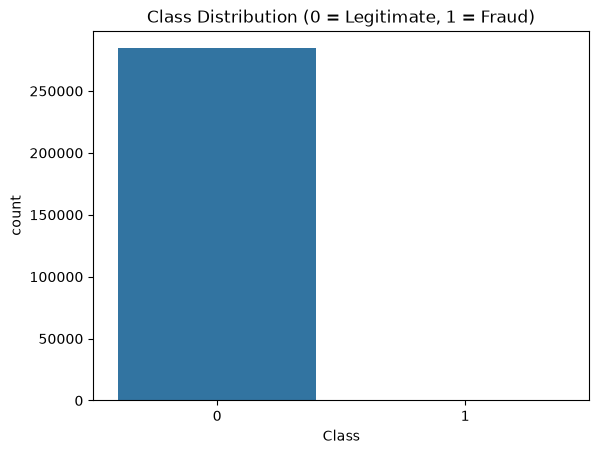

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Class')
plt.title('Class Distribution (0 = Legitimate, 1 = Fraud)')
plt.show()

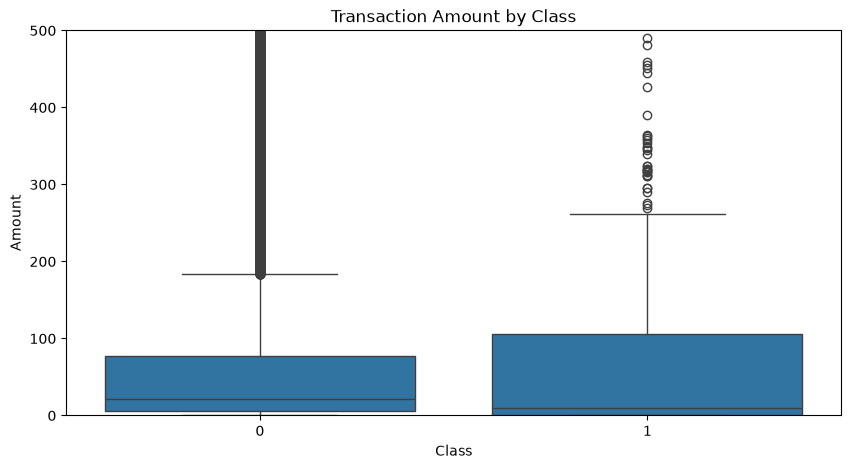

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Class', y='Amount')
plt.title('Transaction Amount by Class')
plt.ylim(0, 500)  # zoom in, since a few huge outliers would squash the plot otherwise
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((227845, 30), (56962, 30))

In [17]:
def true_positives(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 1))

def false_positives(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 1))

def false_negatives(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 0))

def my_precision(y_true, y_pred):
    tp = true_positives(y_true, y_pred)
    fp = false_positives(y_true, y_pred)
    return tp / (tp + fp) if (tp + fp) > 0 else 0

def my_recall(y_true, y_pred):
    tp = true_positives(y_true, y_pred)
    fn = false_negatives(y_true, y_pred)
    return tp / (tp + fn) if (tp + fn) > 0 else 0

def my_f1(y_true, y_pred):
    p = my_precision(y_true, y_pred)
    r = my_recall(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0

In [19]:
import numpy as np
y_true_test = np.array([0, 0, 1, 1, 1])
y_pred_test = np.array([0, 1, 1, 0, 1])
my_precision(y_true_test, y_pred_test), my_recall(y_true_test, y_pred_test), my_f1(y_true_test, y_pred_test)

(np.float64(0.6666666666666666),
 np.float64(0.6666666666666666),
 np.float64(0.6666666666666666))

In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [24]:
my_precision(y_test, y_pred), my_recall(y_test, y_pred), my_f1(y_test, y_pred)

(0.8354430379746836, 0.673469387755102, 0.7457627118644067)

In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)

(0.8354430379746836, 0.673469387755102, 0.7457627118644068)

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
model_scaled = LogisticRegression(max_iter=1000)
model_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = model_scaled.predict(X_test_scaled)

precision_score(y_test, y_pred_scaled), recall_score(y_test, y_pred_scaled), f1_score(y_test, y_pred_scaled)

(0.8266666666666667, 0.6326530612244898, 0.7167630057803468)

In [32]:
model_weighted = LogisticRegression(max_iter=1000, class_weight='balanced')
model_weighted.fit(X_train_scaled, y_train)
y_pred_weighted = model_weighted.predict(X_test_scaled)

precision_score(y_test, y_pred_weighted), recall_score(y_test, y_pred_weighted), f1_score(y_test, y_pred_weighted)

(0.06097560975609756, 0.9183673469387755, 0.11435832274459974)

In [34]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

y_train_smote.value_counts()

Class
0    227451
1    227451
Name: count, dtype: int64

In [36]:
model_smote = LogisticRegression(max_iter=1000)
model_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = model_smote.predict(X_test_scaled)

precision_score(y_test, y_pred_smote), recall_score(y_test, y_pred_smote), f1_score(y_test, y_pred_smote)

(0.057803468208092484, 0.9183673469387755, 0.10876132930513595)

In [38]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(random_state=42, eval_metric='logloss')
model_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = model_xgb.predict(X_test_scaled)

precision_score(y_test, y_pred_xgb), recall_score(y_test, y_pred_xgb), f1_score(y_test, y_pred_xgb)

(0.896551724137931, 0.7959183673469388, 0.8432432432432433)

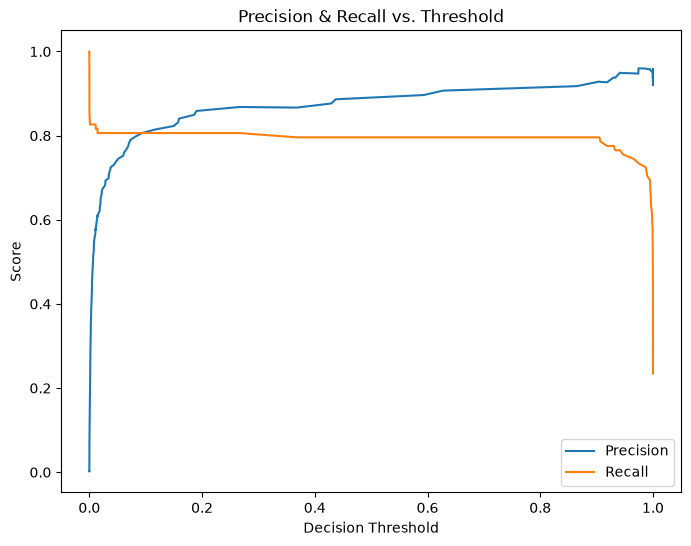

In [40]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

y_scores = model_xgb.predict_proba(X_test_scaled)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision & Recall vs. Threshold')
plt.legend()
plt.show()

In [43]:
import numpy as np

costs = []
for t in thresholds:
    y_pred_t = (y_scores >= t).astype(int)
    fn = ((y_test == 1) & (y_pred_t == 0)).sum()
    fp = ((y_test == 0) & (y_pred_t == 1)).sum()
    total_cost = fn * 500 + fp * 5
    costs.append(total_cost)

best_idx = np.argmin(costs)
best_threshold = thresholds[best_idx]
best_threshold, costs[best_idx]

(np.float32(0.011077398), np.int64(8795))

In [44]:
y_pred_final = (y_scores >= best_threshold).astype(int)
precision_score(y_test, y_pred_final), recall_score(y_test, y_pred_final), f1_score(y_test, y_pred_final)

(0.5785714285714286, 0.826530612244898, 0.680672268907563)

In [45]:
y_pred_default = (y_scores >= 0.5).astype(int)
fn_default = ((y_test == 1) & (y_pred_default == 0)).sum()
fp_default = ((y_test == 0) & (y_pred_default == 1)).sum()
cost_default = fn_default * 500 + fp_default * 5
cost_default

np.int64(10045)